In [19]:
import pandas as pd
import requests
import time
import subprocess
import sys

# Ensure yfinance is installed
try:
    import yfinance as yf
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "yfinance"])
    import yfinance as yf

In [13]:
coins = {
    "bitcoin": "BTC",
    "ethereum": "ETH",
    "solana": "SOL"
}

start_date = "2021-01-01"
end_date = "2026-01-01"

start_timestamp = int(
    pd.Timestamp(start_date, tz="UTC").timestamp()
)

end_timestamp = int(
    pd.Timestamp(end_date, tz="UTC").timestamp()
)

crypto_data = []

In [20]:
def get_crypto_data(coin_id, symbol):
    # Map symbols to Yahoo Finance ticker format (e.g., BTC-USD, ETH-USD, SOL-USD)
    ticker_symbol = f"{symbol}-USD"
    ticker = yf.Ticker(ticker_symbol)

    # Fetch historical daily data using our defined start and end dates
    df = ticker.history(start=start_date, end=end_date, interval="1d")

    if df.empty:
        raise ValueError(f"No data returned for {ticker_symbol}")

    # Format DataFrame to match the requested output structure
    df = df.reset_index()
    df["Date"] = pd.to_datetime(df["Date"], utc=True)
    df["Coin"] = symbol
    df["Close"] = df["Close"]
    df["Volume"] = df["Volume"]

    # Yahoo Finance doesn't directly provide market cap daily history in the same dataframe,
    # but we can use Close * Volume or standard columns.
    # We will compute a Close * Volume metric as a placeholder or simply use Close as Market_Cap proxy
    df["Market_Cap"] = df["Close"] * df["Volume"]

    return df[["Date", "Coin", "Close", "Market_Cap", "Volume"]]

In [22]:
crypto_data = [] # Reset data list before starting downloads

for coin_id, symbol in coins.items():

    print(f"Downloading {symbol}...")

    try:
        data = get_crypto_data(coin_id, symbol)
        crypto_data.append(data)

        print(f"{symbol} downloaded successfully!")

    except Exception as error:
        print(f"Error downloading {symbol}: {error}")

    time.sleep(1)


if crypto_data:

    crypto_df = pd.concat(
        crypto_data, ignore_index=True
    )

    crypto_df.to_csv(
        "crypto_market_data.csv", index=False
    )

    print("\nDownload completed!")

    print(crypto_df.head())
    print(crypto_df.shape)

else:
    print("No data downloaded. Check your connection or source library.")

BTC downloaded successfully!
ETH downloaded successfully!
SOL downloaded successfully!

Download completed!
                       Date Coin         Close    Market_Cap       Volume
0 2021-01-01 00:00:00+00:00  BTC  29374.152344  1.196418e+15  40730301359
1 2021-01-02 00:00:00+00:00  BTC  32127.267578  2.180331e+15  67865420765
2 2021-01-03 00:00:00+00:00  BTC  32782.023438  2.578806e+15  78665235202
3 2021-01-04 00:00:00+00:00  BTC  31971.914062  2.594952e+15  81163475344
4 2021-01-05 00:00:00+00:00  BTC  33992.429688  2.296098e+15  67547324782
(5478, 5)


In [23]:
print(crypto_df.head())

print(crypto_df.info())

print(crypto_df.shape)

print(crypto_df.isnull().sum())

                       Date Coin         Close    Market_Cap       Volume
0 2021-01-01 00:00:00+00:00  BTC  29374.152344  1.196418e+15  40730301359
1 2021-01-02 00:00:00+00:00  BTC  32127.267578  2.180331e+15  67865420765
2 2021-01-03 00:00:00+00:00  BTC  32782.023438  2.578806e+15  78665235202
3 2021-01-04 00:00:00+00:00  BTC  31971.914062  2.594952e+15  81163475344
4 2021-01-05 00:00:00+00:00  BTC  33992.429688  2.296098e+15  67547324782
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5478 entries, 0 to 5477
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype              
---  ------      --------------  -----              
 0   Date        5478 non-null   datetime64[ns, UTC]
 1   Coin        5478 non-null   object             
 2   Close       5478 non-null   float64            
 3   Market_Cap  5478 non-null   float64            
 4   Volume      5478 non-null   int64              
dtypes: datetime64[ns, UTC](1), float64(2), int64(1), object(1)
memory usage: 2

In [24]:
# Check duplicate rows
print("Duplicate rows:", crypto_df.duplicated().sum())

# Check duplicate dates for each coin
print(
    crypto_df.groupby("Coin")["Date"]
    .apply(lambda x: x.duplicated().sum())
)

# Check number of records per coin
print(crypto_df["Coin"].value_counts())

# Check date range
print("Start date:", crypto_df["Date"].min())
print("End date:", crypto_df["Date"].max())

Duplicate rows: 0
Coin
BTC    0
ETH    0
SOL    0
Name: Date, dtype: int64
Coin
BTC    1826
ETH    1826
SOL    1826
Name: count, dtype: int64
Start date: 2021-01-01 00:00:00+00:00
End date: 2025-12-31 00:00:00+00:00


In [25]:
# Statistical summary
print(crypto_df.describe())

               Close    Market_Cap        Volume
count    5478.000000  5.478000e+03  5.478000e+03
mean    19019.903853  8.015050e+14  1.977249e+10
std     30289.556105  1.778638e+15  2.084958e+10
min         1.799275  4.738310e+07  2.572255e+07
25%       157.006351  5.392740e+11  3.400411e+09
50%      2448.949097  4.107109e+13  1.437155e+10
75%     29391.824219  6.865844e+14  2.912320e+10
max    124752.531250  2.178225e+16  3.509679e+11


In [26]:
# Average and maximum values for each coin
print(
    crypto_df.groupby("Coin")[
        ["Close", "Market_Cap", "Volume"]
    ].agg(["mean", "min", "max"])
)

             Close                                 Market_Cap                \
              mean           min            max          mean           min   
Coin                                                                          
BTC   54426.356313  15787.284180  124752.531250  2.349692e+15  1.308045e+14   
ETH    2534.792717    730.367554    4831.348633  5.442848e+13  2.881925e+12   
SOL      98.562529      1.799275     261.869751  3.946510e+11  4.738310e+07   

                          Volume                            
               max          mean         min           max  
Coin                                                        
BTC   2.178225e+16  3.717559e+10  5331172801  350967941479  
ETH   3.756027e+14  1.953862e+10  2081625742   97736621123  
SOL   8.312690e+12  2.603256e+09    25722549   33172955667  


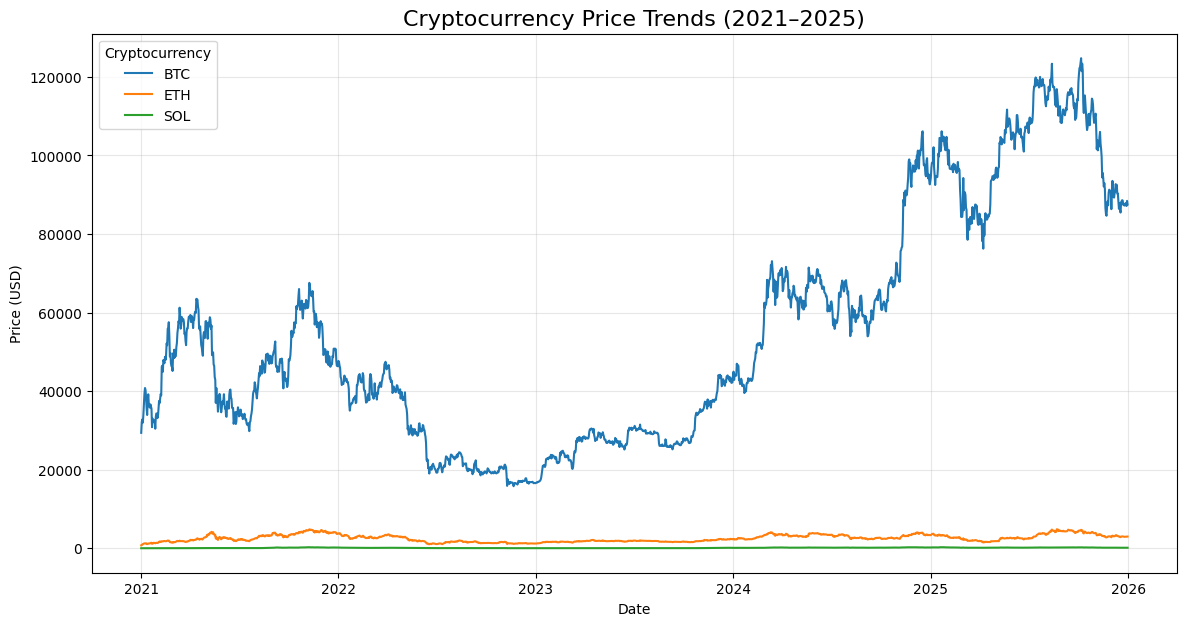

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set chart size
plt.figure(figsize=(14, 7))

# Plot cryptocurrency prices
sns.lineplot(
    data=crypto_df,
    x="Date",
    y="Close",
    hue="Coin"
)

plt.title(
    "Cryptocurrency Price Trends (2021–2025)",
    fontsize=16
)

plt.xlabel("Date")
plt.ylabel("Price (USD)")

plt.legend(title="Cryptocurrency")
plt.grid(True, alpha=0.3)

plt.show()

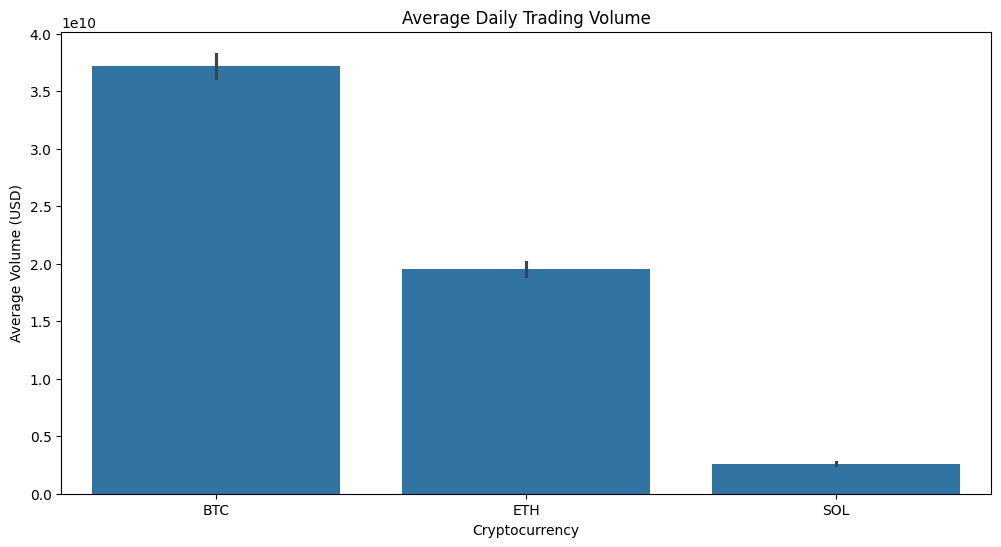

In [28]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=crypto_df,
    x="Coin",
    y="Volume",
    estimator="mean"
)

plt.title("Average Daily Trading Volume")
plt.xlabel("Cryptocurrency")
plt.ylabel("Average Volume (USD)")

plt.show()

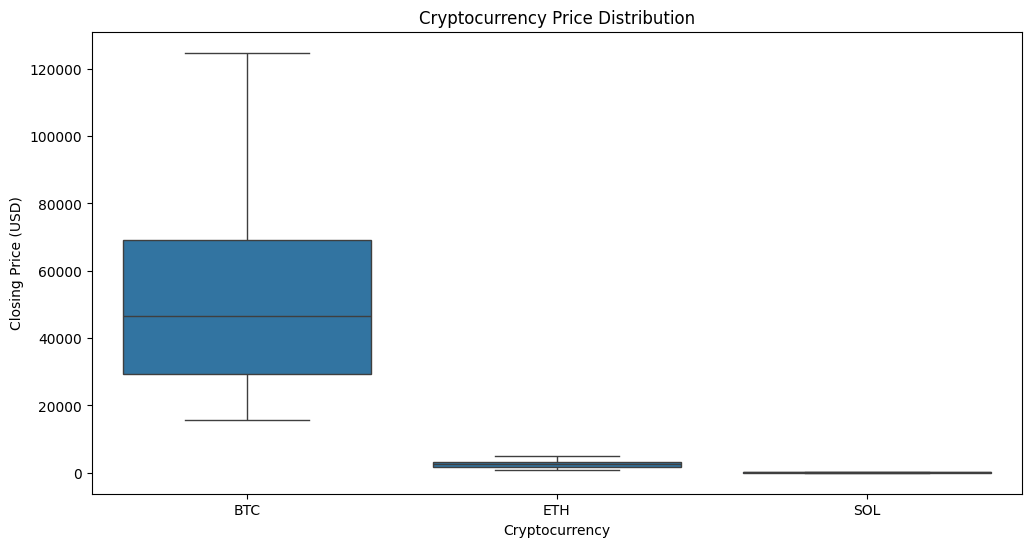

In [29]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=crypto_df,
    x="Coin",
    y="Close"
)

plt.title("Cryptocurrency Price Distribution")
plt.xlabel("Cryptocurrency")
plt.ylabel("Closing Price (USD)")

plt.show()

In [30]:
# Sort data by coin and date
crypto_df = crypto_df.sort_values(
    ["Coin", "Date"]
).copy()

# Calculate daily percentage returns
crypto_df["Daily_Return"] = (
    crypto_df.groupby("Coin")["Close"]
    .pct_change() * 100
)

# Display results
print(
    crypto_df[
        ["Date", "Coin", "Close", "Daily_Return"]
    ].head(10)
)

                       Date Coin         Close  Daily_Return
0 2021-01-01 00:00:00+00:00  BTC  29374.152344           NaN
1 2021-01-02 00:00:00+00:00  BTC  32127.267578      9.372578
2 2021-01-03 00:00:00+00:00  BTC  32782.023438      2.038007
3 2021-01-04 00:00:00+00:00  BTC  31971.914062     -2.471200
4 2021-01-05 00:00:00+00:00  BTC  33992.429688      6.319658
5 2021-01-06 00:00:00+00:00  BTC  36824.363281      8.331071
6 2021-01-07 00:00:00+00:00  BTC  39371.042969      6.915747
7 2021-01-08 00:00:00+00:00  BTC  40797.609375      3.623390
8 2021-01-09 00:00:00+00:00  BTC  40254.546875     -1.331114
9 2021-01-10 00:00:00+00:00  BTC  38356.441406     -4.715257


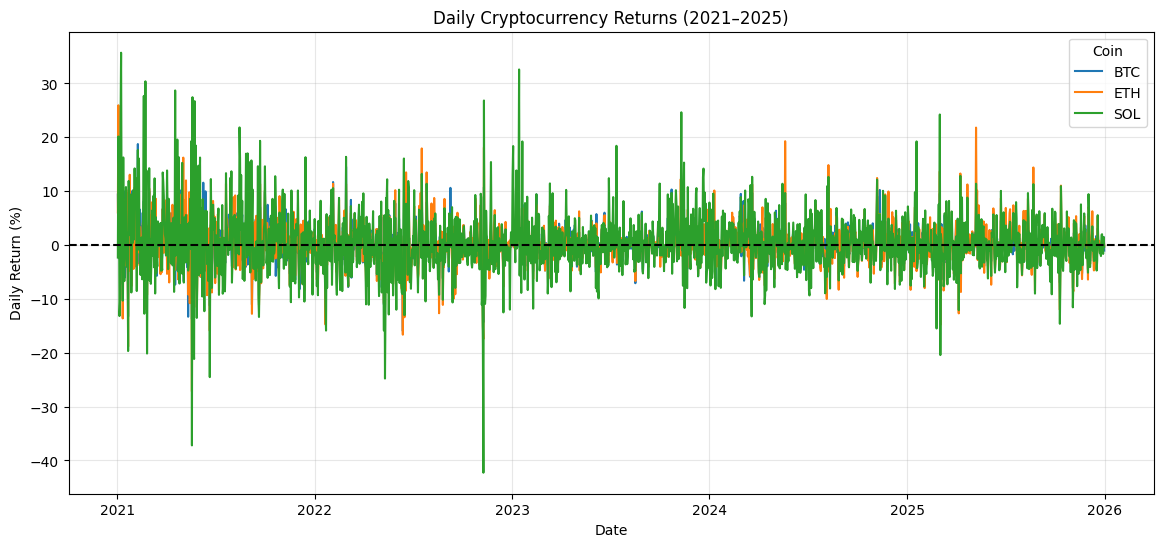

In [31]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=crypto_df,
    x="Date",
    y="Daily_Return",
    hue="Coin"
)

plt.title("Daily Cryptocurrency Returns (2021–2025)")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")

plt.axhline(0, color="black", linestyle="--")

plt.grid(alpha=0.3)
plt.show()

In [32]:
print(
    crypto_df[
        ["Coin", "Close", "Daily_Return"]
    ].groupby("Coin").head(5)
)

     Coin         Close  Daily_Return
0     BTC  29374.152344           NaN
1     BTC  32127.267578      9.372578
2     BTC  32782.023438      2.038007
3     BTC  31971.914062     -2.471200
4     BTC  33992.429688      6.319658
1826  ETH    730.367554           NaN
1827  ETH    774.534973      6.047287
1828  ETH    975.507690     25.947533
1829  ETH   1040.233032      6.635042
1830  ETH   1100.006104      5.746123
3652  SOL      1.842084           NaN
3653  SOL      1.799275     -2.323944
3654  SOL      2.161752     20.145722
3655  SOL      2.485097     14.957541
3656  SOL      2.157217    -13.193848


In [33]:
# Calculate volatility for each cryptocurrency

volatility = crypto_df.groupby("Coin")["Daily_Return"].agg(
    ["mean", "std", "min", "max"]
)

volatility.columns = [
    "Average_Return",
    "Daily_Volatility",
    "Minimum_Return",
    "Maximum_Return"
]

print(volatility)

      Average_Return  Daily_Volatility  Minimum_Return  Maximum_Return
Coin                                                                  
BTC         0.106558          3.059333      -15.974726       18.746474
ETH         0.161735          4.124879      -27.200349       25.947533
SOL         0.407708          5.959447      -42.280904       35.703035


In [37]:
import numpy as np

annual_volatility = (
    crypto_df.groupby("Coin")["Daily_Return"]
    .std() * np.sqrt(365)
) * 100

print("Annualized Volatility (%)")
print(annual_volatility.sort_values(ascending=False))

Annualized Volatility (%)
Coin
SOL    11385.507225
ETH     7880.569745
BTC     5844.848433
Name: Daily_Return, dtype: float64


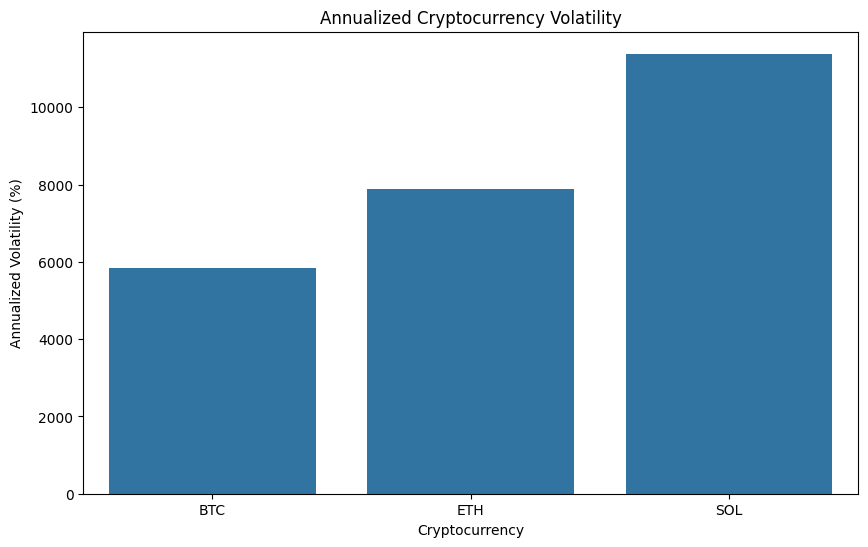

In [38]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=annual_volatility.index,
    y=annual_volatility.values
)

plt.title("Annualized Cryptocurrency Volatility")
plt.xlabel("Cryptocurrency")
plt.ylabel("Annualized Volatility (%)")

plt.show()

In [39]:
annual_volatility = (
    crypto_df.groupby("Coin")["Daily_Return"].std()
    * np.sqrt(365)
)

print("Annualized Volatility (%)")
print(annual_volatility.sort_values(ascending=False))

Annualized Volatility (%)
Coin
SOL    113.855072
ETH     78.805697
BTC     58.448484
Name: Daily_Return, dtype: float64


In [40]:
# Create a table of daily returns

returns_df = crypto_df.pivot(
    index="Date",
    columns="Coin",
    values="Daily_Return"
)

print(returns_df.head())

Coin                            BTC        ETH        SOL
Date                                                     
2021-01-01 00:00:00+00:00       NaN        NaN        NaN
2021-01-02 00:00:00+00:00  9.372578   6.047287  -2.323944
2021-01-03 00:00:00+00:00  2.038007  25.947533  20.145722
2021-01-04 00:00:00+00:00 -2.471200   6.635042  14.957541
2021-01-05 00:00:00+00:00  6.319658   5.746123 -13.193848


In [41]:
# Calculate correlation between cryptocurrencies

correlation = returns_df.corr()

print(correlation)

Coin       BTC       ETH       SOL
Coin                              
BTC   1.000000  0.805685  0.603116
ETH   0.805685  1.000000  0.646475
SOL   0.603116  0.646475  1.000000


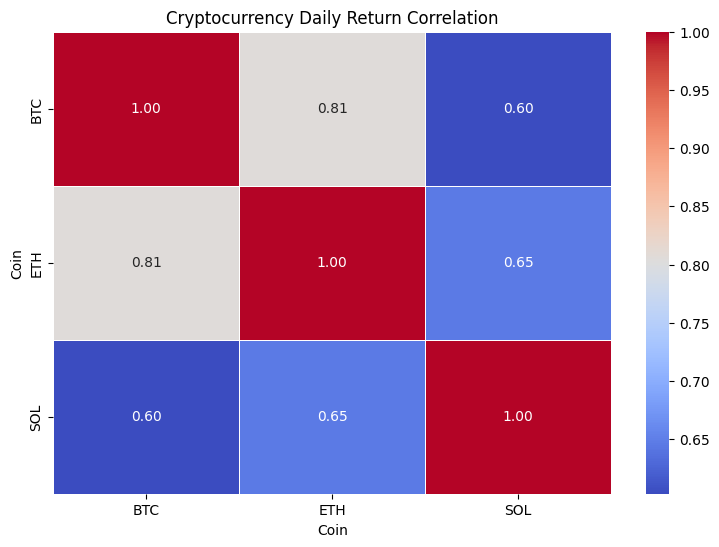

In [42]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Cryptocurrency Daily Return Correlation")

plt.show()

In [43]:
print(correlation)

Coin       BTC       ETH       SOL
Coin                              
BTC   1.000000  0.805685  0.603116
ETH   0.805685  1.000000  0.646475
SOL   0.603116  0.646475  1.000000


In [44]:
# Calculate cumulative returns for each coin

performance = crypto_df.groupby("Coin").apply(
    lambda group: (
        group["Close"].iloc[-1] /
        group["Close"].iloc[0] - 1
    ) * 100,
    include_groups=False
)

performance = performance.sort_values(ascending=False)

print("Cryptocurrency Performance (2021–2025)")
print(performance)

Cryptocurrency Performance (2021–2025)
Coin
SOL    6657.806005
ETH     306.238966
BTC     197.910990
dtype: float64


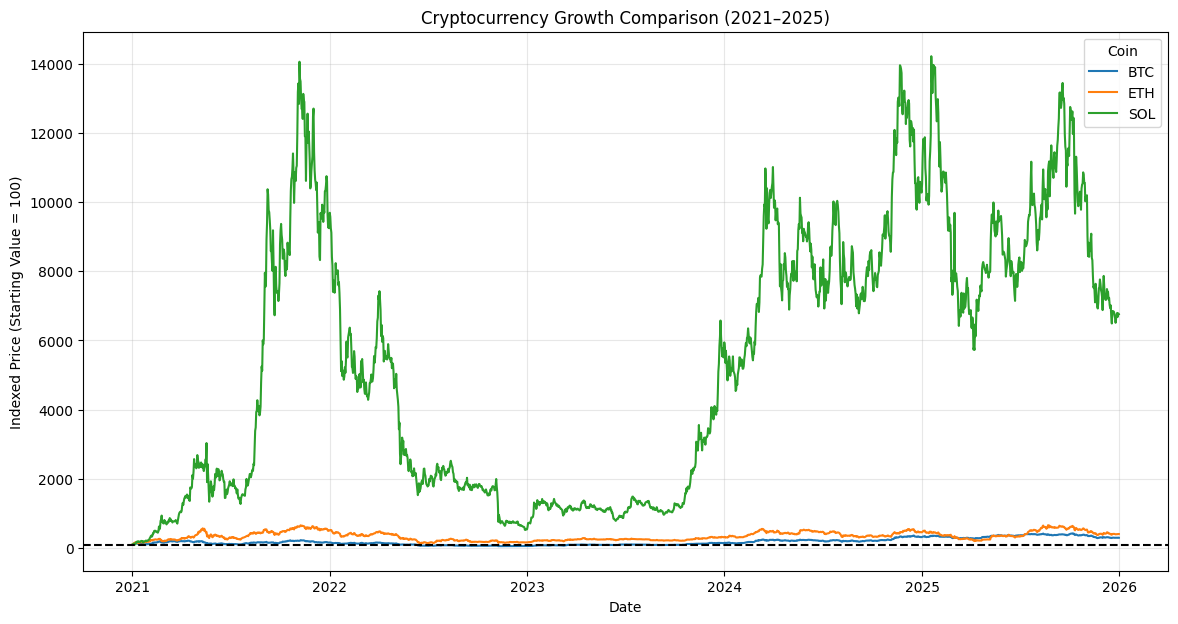

In [45]:

# Create indexed price data

crypto_df["Indexed_Price"] = (
    crypto_df.groupby("Coin")["Close"]
    .transform(lambda x: (x / x.iloc[0]) * 100)
)

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=crypto_df,
    x="Date",
    y="Indexed_Price",
    hue="Coin"
)

plt.title("Cryptocurrency Growth Comparison (2021–2025)")
plt.xlabel("Date")
plt.ylabel("Indexed Price (Starting Value = 100)")

plt.axhline(100, linestyle="--", color="black")
plt.grid(alpha=0.3)

plt.show()

In [46]:
average_returns = (
    crypto_df.groupby("Coin")["Daily_Return"].mean()
)

print("Average Daily Returns (%)")
print(average_returns.sort_values(ascending=False))

Average Daily Returns (%)
Coin
SOL    0.407708
ETH    0.161735
BTC    0.106558
Name: Daily_Return, dtype: float64


In [47]:
crypto_df = crypto_df.sort_values(
    ["Coin", "Date"]
).copy()

crypto_df["MA_30"] = (
    crypto_df.groupby("Coin")["Close"]
    .transform(lambda x: x.rolling(30).mean())
)

crypto_df["MA_90"] = (
    crypto_df.groupby("Coin")["Close"]
    .transform(lambda x: x.rolling(90).mean())
)

print(
    crypto_df[
        ["Date", "Coin", "Close", "MA_30", "MA_90"]
    ].tail(10)
)

                          Date Coin       Close       MA_30       MA_90
5468 2025-12-22 00:00:00+00:00  SOL  125.801231  132.949675  166.887511
5469 2025-12-23 00:00:00+00:00  SOL  123.857216  132.721413  165.910855
5470 2025-12-24 00:00:00+00:00  SOL  122.458603  132.190988  165.133942
5471 2025-12-25 00:00:00+00:00  SOL  119.947121  131.559521  164.184993
5472 2025-12-26 00:00:00+00:00  SOL  122.195953  130.865646  163.280689
5473 2025-12-27 00:00:00+00:00  SOL  124.647713  130.325690  162.324133
5474 2025-12-28 00:00:00+00:00  SOL  125.199356  129.919328  161.347977
5475 2025-12-29 00:00:00+00:00  SOL  123.125229  129.487446  160.396667
5476 2025-12-30 00:00:00+00:00  SOL  124.931320  129.199662  159.321727
5477 2025-12-31 00:00:00+00:00  SOL  124.484467  129.125510  158.095367


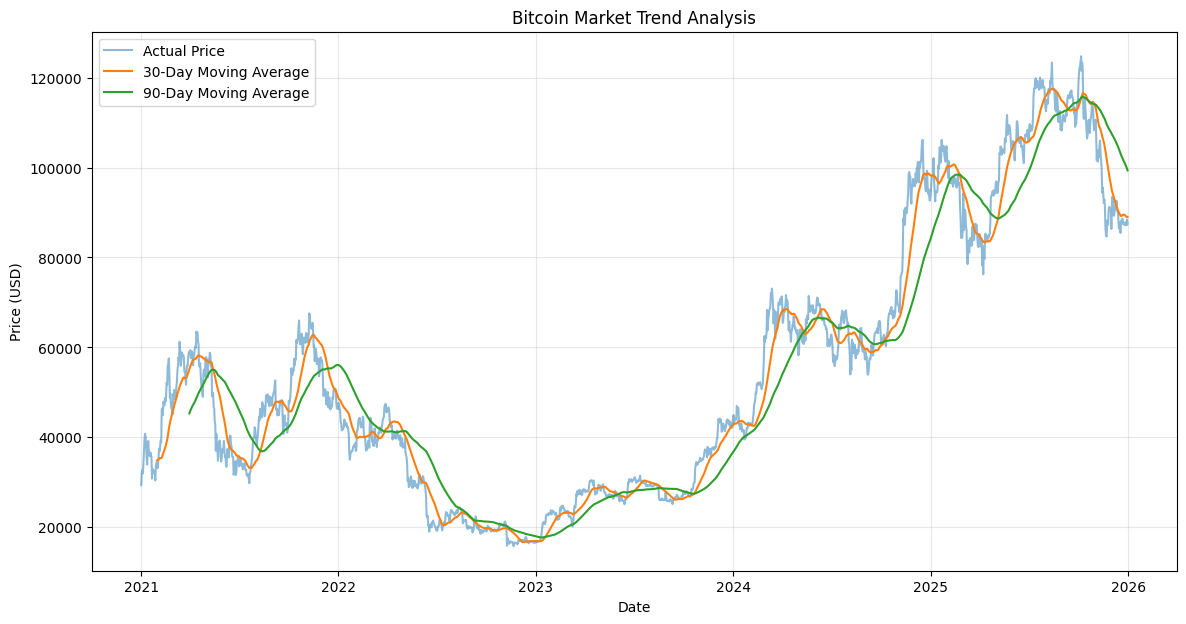

In [48]:

coin = "BTC"

btc = crypto_df[crypto_df["Coin"] == coin]

plt.figure(figsize=(14, 7))

plt.plot(
    btc["Date"], btc["Close"],
    label="Actual Price", alpha=0.5
)

plt.plot(
    btc["Date"], btc["MA_30"],
    label="30-Day Moving Average"
)

plt.plot(
    btc["Date"], btc["MA_90"],
    label="90-Day Moving Average"
)

plt.title("Bitcoin Market Trend Analysis")
plt.xlabel("Date")
plt.ylabel("Price (USD)")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [49]:
latest_trends = (
    crypto_df.sort_values("Date")
    .groupby("Coin")
    .tail(1)
)

print(
    latest_trends[
        ["Coin", "Date", "Close", "MA_30", "MA_90"]
    ].to_string(index=False)
)

Coin                      Date        Close       MA_30        MA_90
 ETH 2025-12-31 00:00:00+00:00  2967.037598  3025.93064  3424.578646
 BTC 2025-12-31 00:00:00+00:00 87508.828125 89013.34375 99357.712326
 SOL 2025-12-31 00:00:00+00:00   124.484467   129.12551   158.095367


In [50]:
def classify_trend(row):

    if row["Close"] > row["MA_30"] > row["MA_90"]:
        return "Bullish"

    elif row["Close"] < row["MA_30"] < row["MA_90"]:
        return "Bearish"

    else:
        return "Neutral"


latest_trends = latest_trends.copy()

latest_trends["Market_Trend"] = latest_trends.apply(
    classify_trend, axis=1
)

print(
    latest_trends[
        ["Coin", "Close", "MA_30", "MA_90", "Market_Trend"]
    ]
)

     Coin         Close        MA_30         MA_90 Market_Trend
3651  ETH   2967.037598   3025.93064   3424.578646      Bearish
1825  BTC  87508.828125  89013.34375  99357.712326      Bearish
5477  SOL    124.484467    129.12551    158.095367      Bearish


In [51]:
import numpy as np

# Convert daily returns from percentages to decimals
daily_returns = crypto_df["Daily_Return"] / 100

crypto_df["Daily_Return_Decimal"] = daily_returns

# Calculate annualised Sharpe Ratio
sharpe_ratio = (
    crypto_df.groupby("Coin")["Daily_Return_Decimal"].mean()
    / crypto_df.groupby("Coin")["Daily_Return_Decimal"].std()
) * np.sqrt(365)

print("Annualised Sharpe Ratio:")
print(sharpe_ratio.sort_values(ascending=False))

Annualised Sharpe Ratio:
Coin
SOL    1.307041
ETH    0.749097
BTC    0.665438
Name: Daily_Return_Decimal, dtype: float64


In [52]:
# Calculate cumulative returns
crypto_df["Cumulative_Return"] = (
    crypto_df.groupby("Coin")["Daily_Return_Decimal"]
    .transform(lambda x: (1 + x).cumprod())
)

# Calculate running maximum
crypto_df["Running_Peak"] = (
    crypto_df.groupby("Coin")["Cumulative_Return"]
    .cummax()
)

# Calculate drawdown
crypto_df["Drawdown"] = (
    crypto_df["Cumulative_Return"] /
    crypto_df["Running_Peak"] - 1
)

# Calculate maximum drawdown
max_drawdown = (
    crypto_df.groupby("Coin")["Drawdown"].min() * 100
)

print("Maximum Drawdown (%):")
print(max_drawdown.sort_values())

Maximum Drawdown (%):
Coin
SOL   -96.272498
ETH   -79.351232
BTC   -76.634564
Name: Drawdown, dtype: float64


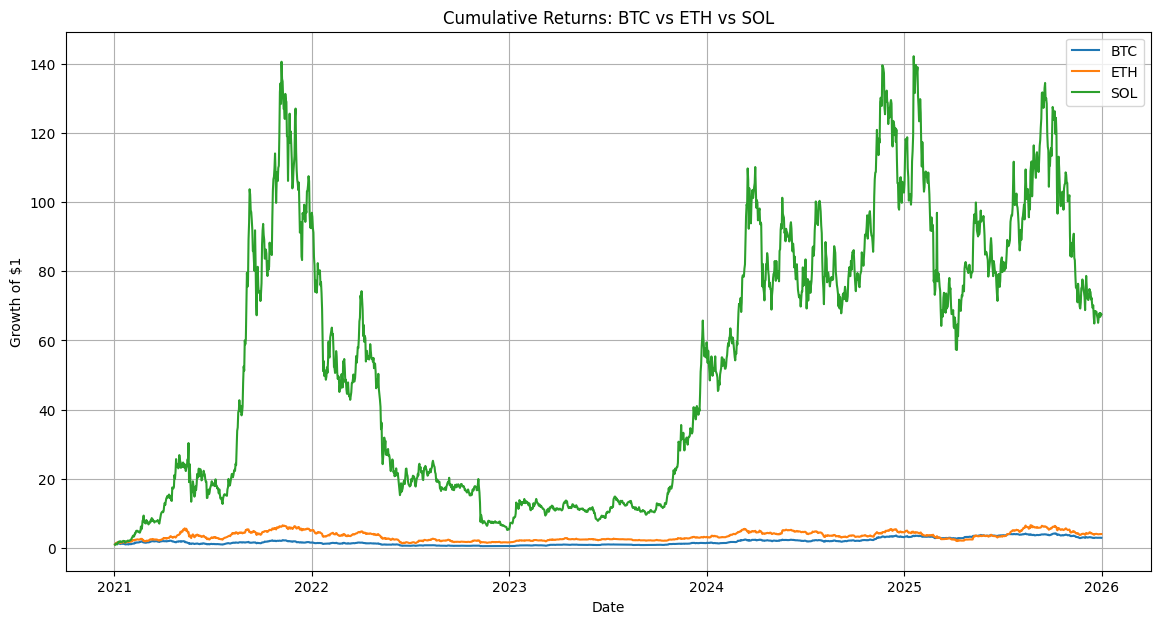

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

for coin in crypto_df["Coin"].unique():
    coin_data = crypto_df[crypto_df["Coin"] == coin]

    plt.plot(
        coin_data["Date"],
        coin_data["Cumulative_Return"],
        label=coin
    )

plt.title("Cumulative Returns: BTC vs ETH vs SOL")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True)
plt.show()

In [54]:
insights = {
    "Bitcoin": [
        "Highest capital preservation among the three",
        "Lowest maximum drawdown"
    ],
    "Ethereum": [
        "Intermediate maximum drawdown",
        "Moderate risk-adjusted performance"
    ],
    "Solana": [
        "Highest Sharpe Ratio",
        "Highest maximum drawdown"
    ]
}

for coin, findings in insights.items():
    print(f"\n{coin}")
    for finding in findings:
        print(f"- {finding}")


Bitcoin
- Highest capital preservation among the three
- Lowest maximum drawdown

Ethereum
- Intermediate maximum drawdown
- Moderate risk-adjusted performance

Solana
- Highest Sharpe Ratio
- Highest maximum drawdown


# Cryptocurrency Market Behaviour and Risk Analysis (2021–2025)

## Conclusion

This project analysed the historical market performance of Bitcoin (BTC), Ethereum (ETH), and Solana (SOL) using Python.

The analysis examined price movements, daily returns, volatility, correlation, moving averages, Sharpe Ratios, and Maximum Drawdowns.

The findings showed that Solana achieved the highest Sharpe Ratio of 1.307, indicating the strongest historical risk-adjusted performance among the three cryptocurrencies. However, it also recorded the largest Maximum Drawdown of -96.27%.

Bitcoin recorded the smallest Maximum Drawdown of -76.63%, suggesting relatively stronger downside protection during the analysed period. Ethereum showed intermediate downside risk.

Overall, the analysis demonstrates that cryptocurrency investments involve different levels of risk and return. Investors should consider multiple financial indicators rather than relying on price performance alone.

## Recommendation

Investors should evaluate historical returns, volatility, risk-adjusted performance, and maximum drawdown before making investment decisions.

Historical performance does not guarantee future results.

In [55]:
!pip install pandas numpy matplotlib seaborn plotly

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("All libraries imported successfully!")

All libraries imported successfully!


In [59]:
fig = px.line(
    crypto_df,
    x="Date",
    y="Close",
    color="Coin",
    title="Cryptocurrency Price Comparison (2021–2025)",
    labels={
        "Date": "Date",
        "Close": "Closing Price (USD)",
        "Coin": "Cryptocurrency"
    }
)

fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    xaxis_title="Date",
    yaxis_title="Price (USD)"
)

fig.show()

In [63]:
# Create daily returns visualisation using the existing 'crypto_df' DataFrame
import plotly.express as px

fig = px.line(
    crypto_df,
    x="Date",
    y="Daily_Return",
    color="Coin",
    title="Daily Cryptocurrency Returns (%)",
    labels={
        "Date": "Date",
        "Daily_Return": "Daily Return (%)",
        "Coin": "Cryptocurrency"
    }
)

fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    xaxis_title="Date",
    yaxis_title="Daily Returns (%)"
)

fig.show()

In [64]:
sharpe_data = pd.DataFrame({
    "Coin": ["BTC", "ETH", "SOL"],
    "Sharpe_Ratio": [0.665, 0.749, 1.307]
})

fig = px.bar(
    sharpe_data,
    x="Coin",
    y="Sharpe_Ratio",
    color="Coin",
    title="Cryptocurrency Sharpe Ratio Comparison",
    text="Sharpe_Ratio"
)

fig.update_layout(
    template="plotly_dark",
    xaxis_title="Cryptocurrency",
    yaxis_title="Sharpe Ratio"
)

fig.show()

In [65]:
drawdown_data = pd.DataFrame({
    "Coin": ["BTC", "ETH", "SOL"],
    "Maximum_Drawdown": [-76.63, -79.35, -96.27]
})

fig = px.bar(
    drawdown_data,
    x="Coin",
    y="Maximum_Drawdown",
    color="Coin",
    title="Maximum Drawdown Comparison",
    text="Maximum_Drawdown"
)

fig.update_layout(
    template="plotly_dark",
    xaxis_title="Cryptocurrency",
    yaxis_title="Maximum Drawdown (%)"
)

fig.show()

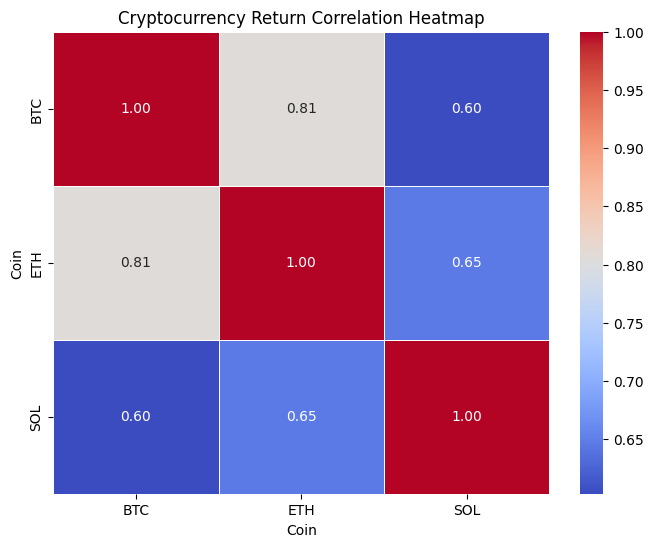

In [67]:
# Calculate correlation between cryptocurrency daily returns using the correct 'crypto_df' DataFrame
returns_pivot = crypto_df.pivot(
    index="Date",
    columns="Coin",
    values="Daily_Return"
)

correlation_matrix = returns_pivot.corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Cryptocurrency Return Correlation Heatmap")
plt.show()

In [69]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# Calculate daily returns
crypto_df["Daily_Return"] = (
    crypto_df.groupby("Coin")["Close"].pct_change() * 100
)

# Calculate correlation
returns_pivot = crypto_df.pivot(
    index="Date",
    columns="Coin",
    values="Daily_Return"
)

correlation_matrix = returns_pivot.corr()

# Create dashboard layout
fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Cryptocurrency Prices",
        "Daily Returns",
        "Sharpe Ratio",
        "Maximum Drawdown"
    )
)

# 1. Price comparison
for coin in crypto_df["Coin"].unique():
    coin_data = crypto_df[crypto_df["Coin"] == coin]

    fig.add_trace(
        go.Scatter(
            x=coin_data["Date"],
            y=coin_data["Close"],
            name=f"{coin} Price"
        ),
        row=1, col=1
    )

# 2. Daily returns
for coin in crypto_df["Coin"].unique():
    coin_data = crypto_df[crypto_df["Coin"] == coin]

    fig.add_trace(
        go.Scatter(
            x=coin_data["Date"],
            y=coin_data["Daily_Return"],
            name=f"{coin} Returns",
            showlegend=False
        ),
        row=1, col=2
    )

# 3. Sharpe Ratio
sharpe_data = pd.DataFrame({
    "Coin": ["BTC", "ETH", "SOL"],
    "Sharpe_Ratio": [0.665, 0.749, 1.307]
})

fig.add_trace(
    go.Bar(
        x=sharpe_data["Coin"],
        y=sharpe_data["Sharpe_Ratio"],
        name="Sharpe Ratio",
        showlegend=False
    ),
    row=2, col=1
)

# 4. Maximum Drawdown
drawdown_data = pd.DataFrame({
    "Coin": ["BTC", "ETH", "SOL"],
    "Drawdown": [-76.63, -79.35, -96.27]
})

fig.add_trace(
    go.Bar(
        x=drawdown_data["Coin"],
        y=drawdown_data["Drawdown"],
        name="Maximum Drawdown",
        showlegend=False
    ),
    row=2, col=2
)

# Dashboard layout
fig.update_layout(
    title_text="Cryptocurrency Market Analysis Dashboard (2021–2025)",
    template="plotly_dark",
    height=850,
    width=1200
)

fig.show()

In [70]:
fig = px.imshow(
    correlation_matrix,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    title="Cryptocurrency Correlation Heatmap",
    aspect="auto",
    zmin=-1,
    zmax=1
)

fig.update_layout(
    template="plotly_dark",
    width=700,
    height=600
)

fig.show()